# PyTorch Workflow Fundamentals

In this module, we're going to cover a standard PyTorch workflow

<!-- ![PyTorch Workflow](../images/01_a_pytorch_workflow.png) -->

```python
TODO

# add table here
```

## Data (Preparing and Loading)

In [2]:
import torch

weight = 0.7
bias = 0.3

start = 0
end = 1
step = 0.02

# X = torch.arange(start, end, step)

In [3]:
X = torch.arange(start, end, step).unsqueeze(dim=1)
y = X * weight + bias
X, y

(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800],
         [0.1000],
         [0.1200],
         [0.1400],
         [0.1600],
         [0.1800],
         [0.2000],
         [0.2200],
         [0.2400],
         [0.2600],
         [0.2800],
         [0.3000],
         [0.3200],
         [0.3400],
         [0.3600],
         [0.3800],
         [0.4000],
         [0.4200],
         [0.4400],
         [0.4600],
         [0.4800],
         [0.5000],
         [0.5200],
         [0.5400],
         [0.5600],
         [0.5800],
         [0.6000],
         [0.6200],
         [0.6400],
         [0.6600],
         [0.6800],
         [0.7000],
         [0.7200],
         [0.7400],
         [0.7600],
         [0.7800],
         [0.8000],
         [0.8200],
         [0.8400],
         [0.8600],
         [0.8800],
         [0.9000],
         [0.9200],
         [0.9400],
         [0.9600],
         [0.9800]]),
 tensor([[0.3000],
         [0.3140],
         [

### Spliting data into training and test sets

We've got some data. However, we need to split it up before we build a model. One of the most important steps in a machine learning project is creating a training and test set.



In [4]:
train_split = int(0.8 * len(X))

X_train, y_train = X[:train_split], y[:train_split]
X_test, y_test = X[train_split:], y[train_split:]

len(X_train), len(y_train), len(X_test), len(y_test)

(40, 40, 10, 10)

In [5]:
A = list()
for i in range(20):
    A.append(i + 1)

train_split = int(0.8 * len(A))

A_train = A[:train_split]
A_test = A[train_split:]
A_train, A_test

([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16], [17, 18, 19, 20])

In [6]:
from matplotlib import pyplot as plt

def plot_predictions(
    train_data: torch.tensor,
    train_labels: torch.tensor,
    test_data: torch.tensor,
    test_labels: torch.tensor,
    predictions=None,
):
    '''
    plots training data, test data and compares predictions
    '''
    plt.figure(figsize=(3,2))

    plt.scatter(train_data, train_labels, c='cyan', s=2, label='Training Data')

    plt.scatter(test_data, test_labels, c='orange', s=2, label='Testing Data')

    if predictions is not None:
        plt.scatter(test_data, predictions, c='r', s=4, label='predictions')

    plt.legend(prop={'size': 14})

### PyTorch model building essentials

PyTorch has four, give or take, essentail modules ywe can use to create almost any kind of neural network we can imagine. They're

| PyTorch module | What does it do? |
|---|---|
| `torch.nn` | Contains all of the building blocks for computational graphs (essentially a series of computations executed in a particular way). |
| `torch.nn.Parameter` | Stores tensors that can be used with `nn.Module`. If `requires_grad=True` gradients (used for updating model parameters via gradient descent) are calculated automatically, this is often referred to as "autograd". |
| `torch.nn.Module` | The base class for all neural network modules, all the building blocks for neural networks are subclasses. If you're building a neural network in PyTorch, your models should subclass `nn.Module`. Requires a `forward()` method be implemented. |
| `torch.optim` | Contains various optimization algorithms (these tell the model parameters stored in `nn.Parameter` how to best change to improve gradient descent and in turn reduce the loss). |
| `def forward()` | All `nn.Module` subclasses require a `forward()` method, this defines the computation that will take place on the data passed to the particular `nn.Module` (e.g. the linear regression formula above). |

If the above soudns complex, think of liek this, almost everything in PyTorch neural network comes from torch.nn

- `nn.Module` contains the larger building blocks
- `nn.Parameter` contains the smaller parameters like weights and biases
- `forward()` tells the larger blocks how to make calculations on inputs, tensors full of data, within `nn.Module`
- `torch.optim` contains optimization methods on how to improve the parameters within `nn.Parameter` to better represent input data.

In [7]:
from torch import nn

# creates a linear regression model in PyTorch
class LinearRegressionModel(nn.Module):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)

        self.weights = nn.Parameter(
            torch.rand(1, dtype=torch.float32), requires_grad=True
        )  # can we update this value with gradient descent?

        self.bias = nn.Parameter(torch.rand(1, dtype=torch.float32), requires_grad=True)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return x * self.weights + self.bias  # this is linear regression formula

### Checking contents of a PyTorch model

Now we've got these out of the way, let's create a model instance with the class we've made and check its parameters using `.parameters()`

In [8]:
torch.manual_seed(seed=69)

model_0 = LinearRegressionModel()

list(model_0.parameters())

[Parameter containing:
 tensor([0.8398], requires_grad=True),
 Parameter containing:
 tensor([0.8042], requires_grad=True)]

we can also tget the state (_what the model contains_) of the model using `.state_dict()`.

In [9]:
model_0.state_dict()

OrderedDict([('weights', tensor([0.8398])), ('bias', tensor([0.8042]))])

notice how the values for `weights` and `bias` from `model_0.state_dict()` come out as random float tensors?

This is because we initialized them above using torch.randn().

Essentially we want to start from random parameters and get the model to update them towards parameters that fit our data best.

Because our model starts with random values, it will have poor predictive power right now.

### Making predictions using `torch.inference_mode()`

To check this we can pass it the test data X_test to see how closely it predicts y_test. When we pass data to our model, it will go through the model's `forward` method and produce a result using the computation we've defined.

Let's make some predictions

In [14]:
# Make predictions with model

with torch.inference_mode():
    y_preds = model_0(X_test)

# note: in older PyTorch code you might also see torch.no_grad()
# with torch.no_grad():
#     y_preds = model_0(X_test)

We probably noticed we used `torch.inference_mode()` as a context manager. **_that's what the `with torch.inference_mode():` is_** to make the predictions


As the name suggests, `torch.inference_mode()` is used when using a model for inference _**making predictions**_


`torch.inference_mode()` turns off a bunch of things , **_like gradient tracking, which is necessary for training but not for inference_**m, to make forward-pass,  **_data going through the `forward()` method_**

In [15]:
# Check the predictions
print(f'number of testing samples: {len(X_test)}')
print(f'number of predictions made: {len(y_preds)}')
print(f'printed values: \n {y_preds}')

number of testing samples: 10
number of predictions made: 10
printed values: 
 tensor([[1.4760],
        [1.4928],
        [1.5096],
        [1.5264],
        [1.5432],
        [1.5600],
        [1.5768],
        [1.5935],
        [1.6103],
        [1.6271]])


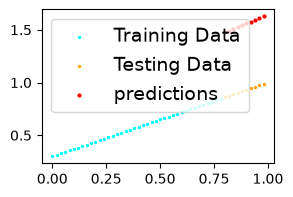

In [16]:
plot_predictions(
    train_data=X_train, 
    train_labels=y_train, 
    test_data=X_test,
    test_labels=y_test, 
    predictions=y_preds
    )

In [17]:
y_test - y_preds

tensor([[-0.6160],
        [-0.6188],
        [-0.6216],
        [-0.6244],
        [-0.6272],
        [-0.6300],
        [-0.6328],
        [-0.6355],
        [-0.6383],
        [-0.6411]])

Woah! Those predictions look pretty bad.

This makes sense though, when you remember our model is just using random parameter values to make predictions.

It hasn't even looked at the blue dots to try to predict the green dots.

Time to change that.

## 3. Train Model

Right now, our model is making predictions using random parameters to make calculations it's basically guessing (randomly). To fix that, we can update its internal parmeters, the `weights` and `bias` values we set randomly using `nn.Parameter()` and `torch.rand()` to be something that better represents data. We could hardcode this but where's the fun in that?

Much of the time we won't know  what the ideal parameters are for a model.

Instead, it's much more fu nto write code to see if the model can try and figure them out itself.


### Creating a loss function and optimizer in PyTorch

For our model to update its parmeters on its own, we'll need to add a few more things to our recipe. That's a loss function a s well as an optimizer. The rools of these are:

- Loss function measures how wrong our model's predictions are compared to the ground truth. PyTorch has plenty of built-in loss functions in `torch.nn`. Mean absoluate error (MAE) for regression and cross entropy for classification.

- Optimizer tells your model how

Let's create a loss function and an optimizer we can use to help improve our model. Depending on what kind of problem we're working on will depend on what loss function and what optimizer we use.

However, there are some common values, that are known to work well such as the stochastic gradient descent or Adam optimizer and mean absolute error loss function for regression problems or binary cross entropy loss function for classification problems.

For our problems, since we're predicting a number, let's use MAE.